# 4. From code to circuit to detector graph

Hardware measures checks with ancilla qubits and CNOTs, and every gate can fail. We write that circuit for any CSS code; Stim runs it.

The result to look for: surface-code faults light at most 2 detectors, so decoding is a graph problem. Gross-code faults light up
to 9, so it is a hypergraph problem.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))      # make the repo's qdec package importable
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(2026)                        # fixed seed: same pictures every run
from qdec.families import surface_rotated, toric, bb, steane, repetition
from qdec.circuits import memory_circuit, circuit_stats, circuit_distance, cnot_layers
from qdec.dem import fault_degree_histogram, MatchingGraph, DecodingProblem, draw_detector_graph_3d

## Writing the circuit

Each round: reset the ancillas, run the $X$-check CNOTs, measure, run the $Z$-check CNOTs, measure. A detector compares each
measurement with the previous round. Without noise, no detector may ever fire.

In [2]:
for code in [repetition(5), steane(), surface_rotated(3), toric(4), bb("bb72"), bb("gross")]:
    c = memory_circuit(code, rounds=3, p=0.0)
    silent = not c.compile_detector_sampler().sample(200, append_observables=True).any()
    print(f"{code.name:24s} silent without noise: {silent}   {circuit_stats(c)}")

repetition d=5           silent without noise: True   {'CX': 24, 'ticks': 10, 'detectors': 16, 'observables': 1, 'qubits': 9}
Steane [[7,1,3]]         silent without noise: True   {'CX': 72, 'ticks': 34, 'detectors': 18, 'observables': 1, 'qubits': 13}
surface (rotated) d=3    silent without noise: True   {'CX': 72, 'ticks': 28, 'detectors': 24, 'observables': 1, 'qubits': 17}
toric 4x4                silent without noise: True   {'CX': 384, 'ticks': 28, 'detectors': 96, 'observables': 2, 'qubits': 64}
BB [[72,12,6]]           silent without noise: True   {'CX': 1296, 'ticks': 40, 'detectors': 216, 'observables': 12, 'qubits': 144}


gross [[144,12,12]]      silent without noise: True   {'CX': 2592, 'ticks': 40, 'detectors': 432, 'observables': 12, 'qubits': 288}


In [3]:
c = memory_circuit(surface_rotated(3), rounds=2, p=0.0)
print(c)          # the actual instructions we generated (Stim's text format)

QUBIT_COORDS(1, 1) 0
QUBIT_COORDS(3, 1) 1
QUBIT_COORDS(5, 1) 2
QUBIT_COORDS(1, 3) 3
QUBIT_COORDS(3, 3) 4
QUBIT_COORDS(5, 3) 5
QUBIT_COORDS(1, 5) 6
QUBIT_COORDS(3, 5) 7
QUBIT_COORDS(5, 5) 8
QUBIT_COORDS(4, 0) 9
QUBIT_COORDS(2, 2) 10
QUBIT_COORDS(4, 4) 11
QUBIT_COORDS(2, 6) 12
QUBIT_COORDS(0, 2) 13
QUBIT_COORDS(4, 2) 14
QUBIT_COORDS(2, 4) 15
QUBIT_COORDS(6, 4) 16
R 0 1 2 3 4 5 6 7 8
TICK
RX 9 10 11 12
R 13 14 15 16
TICK
CX 10 0 11 4 12 6
TICK
CX 10 1 11 5 12 7
TICK
CX 9 1 10 3 11 7
TICK
CX 9 2 10 4 11 8
TICK
MX(0) 9 10 11 12
CX 1 14 3 15 5 16
TICK
CX 4 14 6 15 8 16
TICK
CX 0 13 2 14 4 15
TICK
CX 3 13 5 14 7 15
TICK
M(0) 13 14 15 16
DETECTOR(0, 2, 0) rec[-4]
DETECTOR(4, 2, 0) rec[-3]
DETECTOR(2, 4, 0) rec[-2]
DETECTOR(6, 4, 0) rec[-1]
RX 9 10 11 12
R 13 14 15 16
TICK
CX 10 0 11 4 12 6
TICK
CX 10 1 11 5 12 7
TICK
CX 9 1 10 3 11 7
TICK
CX 9 2 10 4 11 8
TICK
MX(0) 9 10 11 12
CX 1 14 3 15 5 16
TICK
CX 4 14 6 15 8 16
TICK
CX 0 13 2 14 4 15
TICK
CX 3 13 5 14 7 15
TICK
M(0) 13 14 15 16
DETECTOR(

## One polynomial term, one CNOT layer

On the gross code, each of the six terms of $A$ and $B$ becomes one layer of 72 CNOTs, with no qubit used twice.

In [4]:
g = bb("gross")
for kind in "XZ":
    L = cnot_layers(g, kind)
    print(f"{kind} checks: {len(L)} layers of sizes {[len(x) for x in L]}")

X checks: 6 layers of sizes [72, 72, 72, 72, 72, 72]
Z checks: 6 layers of sizes [72, 72, 72, 72, 72, 72]


## Hook errors

A fault on an ancilla halfway through its CNOTs spreads to two data qubits. If that pair lies along a logical operator, the circuit
loses distance. For the rotated surface code the safe order is a Z shape for $X$ checks and an N shape for $Z$ checks
(Tomita & Svore, PRA 90, 062320).

d=3 Z-memory: hook-safe order -> circuit distance 3;  plain order -> 3
d=3 X-memory: hook-safe order -> circuit distance 3;  plain order -> 2


d=5 Z-memory: hook-safe order -> circuit distance 5;  plain order -> 5


d=5 X-memory: hook-safe order -> circuit distance 5;  plain order -> 3


d=7 Z-memory: hook-safe order -> circuit distance 7;  plain order -> 7


d=7 X-memory: hook-safe order -> circuit distance 7;  plain order -> 4


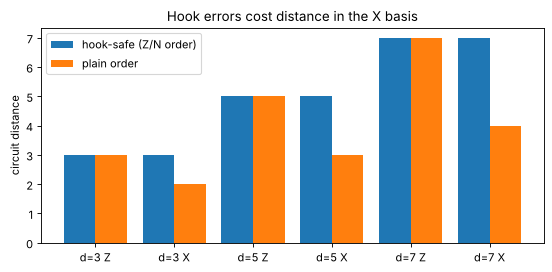

In [5]:
rows = []
for d in (3, 5, 7):
    for basis in "ZX":
        good = circuit_distance(memory_circuit(surface_rotated(d), 3, 0.001, basis))
        plain = circuit_distance(memory_circuit(surface_rotated(d), 3, 0.001, basis, order="plain"))
        rows.append((d, basis, good, plain))
        print(f"d={d} {basis}-memory: hook-safe order -> circuit distance {good};  plain order -> {plain}")
fig, ax = plt.subplots(figsize=(7, 3.5))
lab = [f"d={d} {b}" for d, b, *_ in rows]
ax.bar(np.arange(len(rows)) - 0.2, [r[2] for r in rows], 0.4, label="hook-safe (Z/N order)")
ax.bar(np.arange(len(rows)) + 0.2, [r[3] for r in rows], 0.4, label="plain order")
ax.set_xticks(range(len(rows)), lab); ax.set_ylabel("circuit distance"); ax.legend(); ax.set_title("Hook errors cost distance in the X basis")
plt.tight_layout(); plt.show()

## Graph or hypergraph?

Count how many detectors each fault lights.

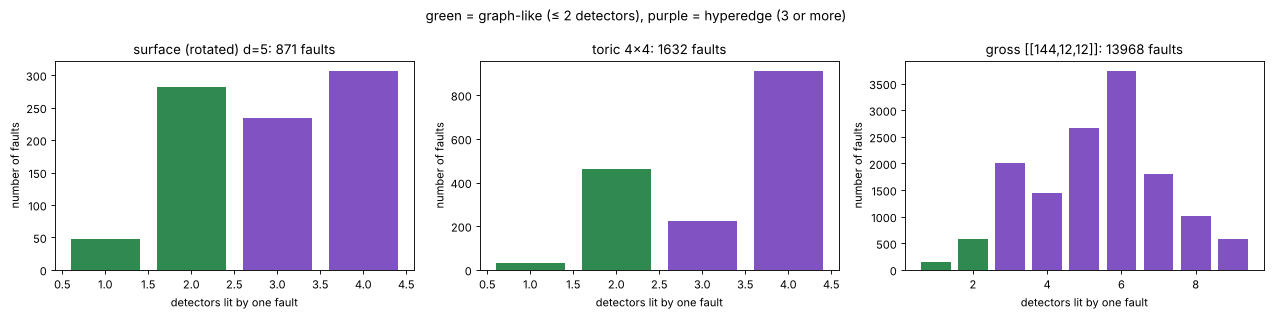

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, code in zip(axs, [surface_rotated(5), toric(4), bb("gross")]):
    dem = memory_circuit(code, 3, 0.001).detector_error_model(approximate_disjoint_errors=True)
    h = fault_degree_histogram(dem)
    ks = sorted(h)
    ax.bar(ks, [h[k] for k in ks], color=["#2f8a4f" if k <= 2 else "#8152c2" for k in ks])
    ax.set_title(f"{code.name}: {sum(h.values())} faults"); ax.set_xlabel("detectors lit by one fault"); ax.set_ylabel("number of faults")
plt.suptitle("green = graph-like (≤ 2 detectors), purple = hyperedge (3 or more)"); plt.tight_layout(); plt.show()

In [7]:
# Surface code: Stim can split every 3-4 detector fault (Y errors) into graph-like pieces. Gross code: it cannot.
dem_s = memory_circuit(surface_rotated(5), 3, 0.001).detector_error_model(decompose_errors=True, approximate_disjoint_errors=True)
print("surface d=5, after splitting: pieces by size", dict(sorted(fault_degree_histogram(dem_s, use_parts=True).items())))
print(MatchingGraph(dem_s))
try:
    memory_circuit(bb("gross"), 3, 0.001).detector_error_model(decompose_errors=True)
except ValueError as e:
    print("gross code:", str(e).splitlines()[0][:110], "...")

surface d=5, after splitting: pieces by size {1: 886, 2: 1066}
MatchingGraph(72 detectors + boundary, 286 edges, 0 faults not graph-like)


gross code: Failed to decompose errors into graphlike components with at most two symptoms. ...


## Detectors in space and time

Each dot is a detector at (x, y, round). Grey: faults within a round. Orange: faults across rounds. Purple: hyperedges.

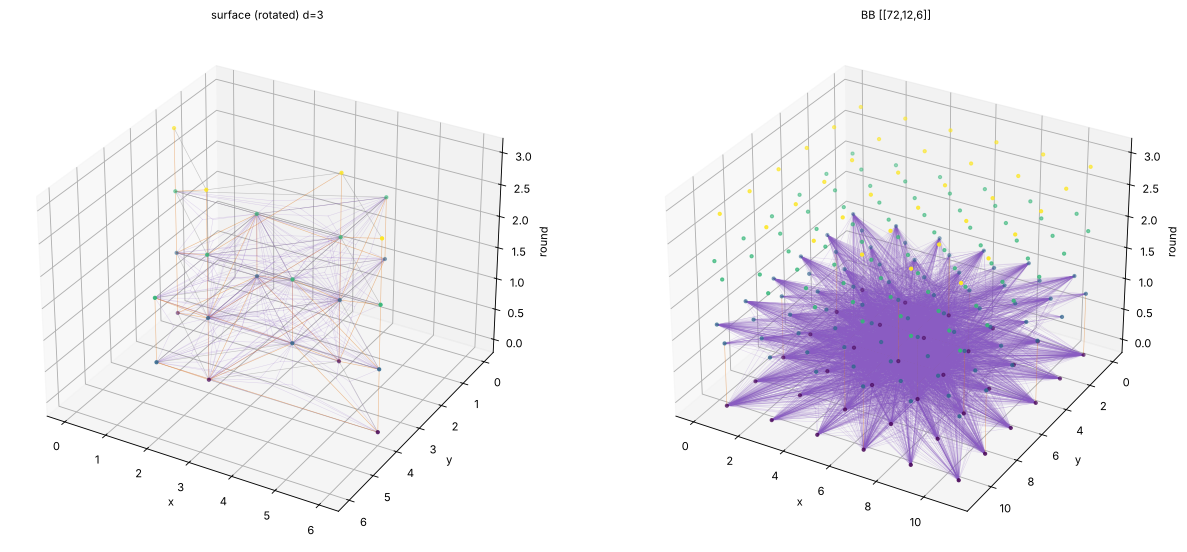

In [8]:
fig = plt.figure(figsize=(16, 7))
for i, code in enumerate([surface_rotated(3), bb("bb72")]):
    ax = fig.add_subplot(1, 2, i + 1, projection="3d")
    dem = memory_circuit(code, 3, 0.001).detector_error_model(approximate_disjoint_errors=True)
    draw_detector_graph_3d(dem, ax, max_faults=1500 if i else 4000, title=code.name)
plt.tight_layout(); plt.show()

## What the decoder gets

`DecodingProblem` holds $H$ (detectors by faults), $L$ (observables by faults) and the fault probabilities. BP, OSD and lookup all
read this one object.

In [9]:
for code in [surface_rotated(5), bb("gross")]:
    pb = DecodingProblem.from_dem(memory_circuit(code, code.info["d_known"] if code.n < 100 else 6, 0.001).detector_error_model(approximate_disjoint_errors=True))
    print(f"{code.name:22s} code H_Z: {code.HZ.shape}   circuit-level H: {pb.H.shape}   observables: {pb.L.shape[0]}")

surface (rotated) d=5  code H_Z: (12, 25)   circuit-level H: (120, 1687)   observables: 1


gross [[144,12,12]]    code H_Z: (72, 144)   circuit-level H: (864, 31680)   observables: 12
